In [31]:
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from datetime import datetime
import os as os 
import numpy as np
import cmocean
import netCDF4 as nc
from cartopy.feature import LAND
from cartopy.feature import ShapelyFeature
import xarray as xr
import geopandas as gpd
import os as os 
import scipy
import cfgrib
# import fonctions as funcs

#For TOEddies
import sys

import pandas as pd
from pathlib import Path
from datetime import datetime, timedelta
from pyproj import Geod
import numpy as np
import matplotlib.lines as mlines
from matplotlib.patches import FancyArrowPatch
from ladcp_tools import *
import os
from tools import *

In [41]:
lon_min, lon_max, lat_min, lat_max = 8, 20, -41, -34
pos_west,pos_east,pos_south,pos_north  = lon_min, lon_max, lat_min, lat_max  #Reset the area
curr_date = "2026-07-02"
ft=10


In [42]:
dir_ladcp = "/home/geosciences/Documents/Gurcan/data/LADCP/traitement_avec_SADCP/"
dir_eddies = "/home/geosciences/Documents/Gurcan/data/TOEDDIES/TOEDDIES_better_ADT/"
dir_ssh = "/home/geosciences/Documents/Gurcan/data/SSH/"
fname_bathy = "/home/geosciences/Documents/Gurcan/WHIRLS_eddies/REP/data/bathymetry/etopo2.nc"

In [43]:
daily_ssh_files = sorted(os.listdir(dir_ssh))
curr_ssh = next(f for f in daily_ssh_files if curr_date in f)
ssh = load_satellite(dir_ssh + curr_ssh)

In [44]:
daily_eddy_files = sorted(os.listdir(dir_eddies))
eddy_files = [dir_eddies + f for f in daily_eddy_files if curr_date.replace("-", "") in f]

In [45]:
##### BATHYMETRY #####
bathymetry_data = xr.open_dataset(fname_bathy)
land_feature = cfeature.NaturalEarthFeature(
    category='physical',
    name='land',
    scale='10m',
    edgecolor='black',
    facecolor='gray'
)

# Extract relevant variables (e.g., longitude, latitude, depth)
lon = bathymetry_data['lon']
lat = bathymetry_data['lat']
depth = bathymetry_data['topo']
LON = bathymetry_data['lon']
LAT = bathymetry_data['lat']
depth = bathymetry_data['topo']
lon_subset = LON.sel(lon=slice(lon_min, lon_max))
lat_subset = LAT.sel(lat=slice(lat_min, lat_max))
depth_subset = depth.sel(lon=slice(lon_min, lon_max), lat=slice(lat_min, lat_max))


Found 58 stations in /home/geosciences/Documents/Gurcan/data/LADCP/traitement_avec_SADCP/


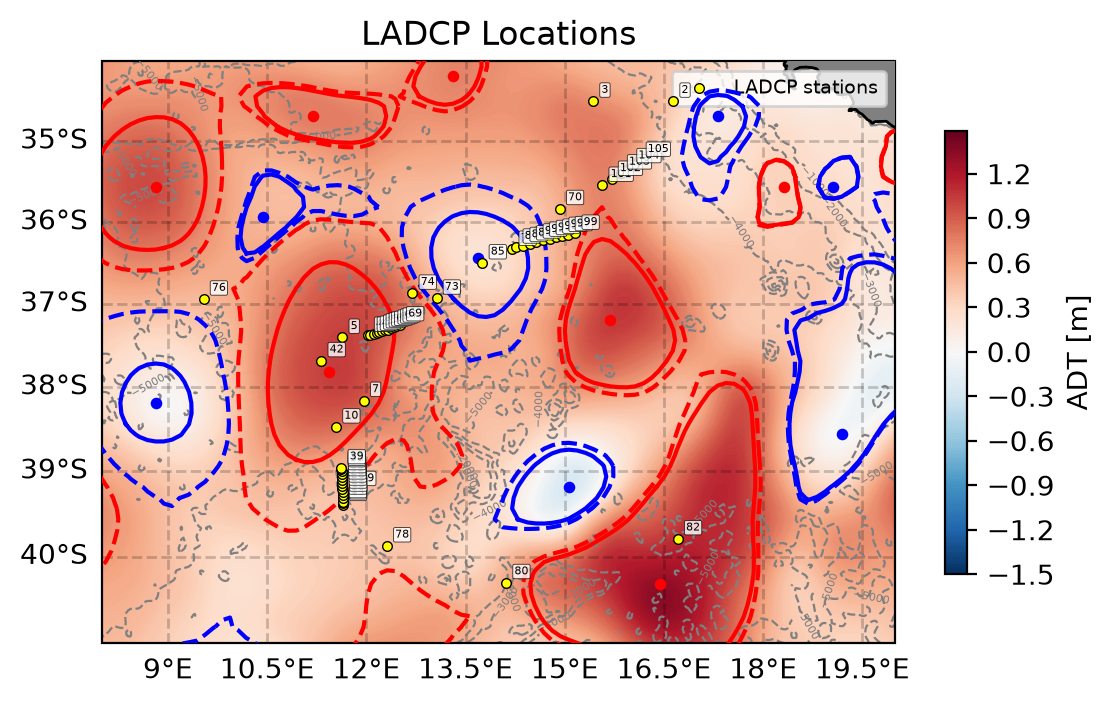

In [46]:
crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)
cartmap = proj,crs,extent

fig = plt.figure(dpi=200)
ax = fig.add_subplot(111, projection=proj)

title = "LADCP Locations"
setup_map(ax, extent, title, crs, ft)

vmin = -1.5
vmax = 1.5
bathy = ax.contour(
    lon_subset,
    lat_subset,
    depth_subset,
    colors="grey",
    linewidths=0.8,
    transform=crs,
)

ax.clabel(bathy, fontsize=4)

c = ax.contourf(
    ssh["lon"],
    ssh["lat"],
    ssh["adt"][0],
    levels=np.arange(vmin, vmax, 0.01),
    cmap="RdBu_r",
    transform=crs,
)
anti, cyc = load_eddies(eddy_files)
plot_eddies(ax, anti, "red", crs)
plot_eddies(ax, cyc, "blue", crs)

st = load_all_stations(dir_ladcp)

# Keep only stations inside the map, so labels don't spill outside the frame
inside = st[(st.lon >= extent[0]) & (st.lon <= extent[1]) &
            (st.lat >= extent[2]) & (st.lat <= extent[3])]

ax.scatter(inside.lon, inside.lat, s=12, color="yellow", edgecolors="black",
           linewidths=0.5, zorder=100, transform=crs, label="LADCP stations")

# Station number next to each point
for _, s in inside.iterrows():
    ax.annotate(str(int(s.station)), xy=(s.lon, s.lat),
                xycoords=crs._as_mpl_transform(ax),
                xytext=(3, 3), textcoords="offset points",
                fontsize=4, zorder=101,
                bbox=dict(boxstyle="round,pad=0.15", facecolor="white",
                          edgecolor="black", linewidth=0.3, alpha=0.8))

ax.legend(fontsize="x-small", loc="upper right")

cb = fig.colorbar(c, ax=ax, shrink=0.6)
cb.set_label("ADT [m]")

In [7]:
meta, df = read_lad(dir_ladcp + "002/002.lad")
# plot_profile(dir_ladcp + "002/002.lad")